# Fitting the exponential map to experimental CA1 place cells

First fit of the exponential map to the place-cell population built in notebook 10, without
regard to extrapolation: can generators $G_x, G_y$ be found that transport the pooled
population vector across the arena so that the measured ratemaps are reproduced?

The procedure is Appendix K's, unchanged: the one-step prediction loss over random
displacements of up to two pixels, a commutator penalty, skew-symmetry imposed structurally
as $G = A - A^\top$, Adam for 20 000 steps (`expmap.fitting.GeneratorFit`). The only new
choice is the scale: the ratemaps are in Hz and are divided by one global constant so that
their maximum equals the grid-cell file's, which keeps the published hyperparameters and the
balance between the two loss terms meaningful. A single global scale is a change of units; a
per-unit scale would be a diagonal similarity transform that breaks skew-symmetry, so it is
not used.

**Population.** Single-field units from `data/ca1_ratemaps.npz` (97 units), border-like ones
included since the fit does not care where a field sits. The stricter rule is available as
constants below.

**What to expect.** Skew-symmetric transport keeps $\|\mathbf{p}\|$ constant, so the model
can only reproduce a population whose norm is roughly uniform across the arena, as a
population of grid cells with phases covering the plane is. Ninety-seven place fields pooled
across animals cover the arena unevenly, so the first thing measured is the data's own norm
map; its variation bounds what any orthogonal model can achieve.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.fitting import GeneratorFit, generator_diagnostics, pixels_to_arena, sample_displacements

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
FIGURE_DIR = REPO_ROOT / "figures"
DATA = REPO_ROOT / "data" / "ca1_ratemaps.npz"
GRID_DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"
OUTPUT = REPO_ROOT / "data" / "ca1_fit.npz"

# Population rule (see notebook 10). None disables a criterion.
MAX_FIELDS = 1
MAX_BORDER = None  # 0.5 drops border-like units
MIN_STABILITY = None  # 0.5 drops units whose halves disagree

# Fit parameters, as published for the grid cells (App. K).
N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2
LR = 1e-3
COMMUTATOR_WEIGHT = 1.0
ARENA_SIZE = 1.0
SEED = 0

In [2]:
d = np.load(DATA)
keep = d["n_fields"] <= MAX_FIELDS
if MAX_BORDER is not None:
    keep &= ~(d["border_score"] > MAX_BORDER)
if MIN_STABILITY is not None:
    keep &= d["stability"] >= MIN_STABILITY
experimental_hz = d["ratemaps"][keep]

# One global scale to the grid-cell file's maximum; the ratemaps are in Hz.
grid_max = float(np.load(GRID_DATA).max())
SCALE = grid_max / experimental_hz.max()
experimental = (experimental_hz * SCALE).astype("float32")
ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))  # (bins_x, bins_y, n_units)

N_UNITS, N_BINS = experimental.shape[0], experimental.shape[1]
print(f"{N_UNITS} units, {N_BINS} x {N_BINS} bins, scale {SCALE:.4f} per Hz (max {experimental_hz.max():.1f} Hz -> {grid_max})")
print("units per animal:", {a: int((d["animal"][keep] == a).sum()) for a in np.unique(d["animal"])})

97 units, 32 x 32 bins, scale 0.0049 per Hz (max 40.6 Hz -> 0.1998630300365036)
units per animal: {np.str_('24101'): 10, np.str_('24116'): 6, np.str_('25398'): 50, np.str_('26019'): 12, np.str_('26191'): 19}


## Is the population equinorm?

$\|\mathbf{p}(x, y)\|$ over the arena for the data, with the coefficient of variation. The
model's generated maps have a constant norm, so this is the floor on the reconstruction
error of any skew-symmetric fit, independent of training. The grid-cell file is shown for
comparison.

relative error floor from norm variation alone: 25.1%


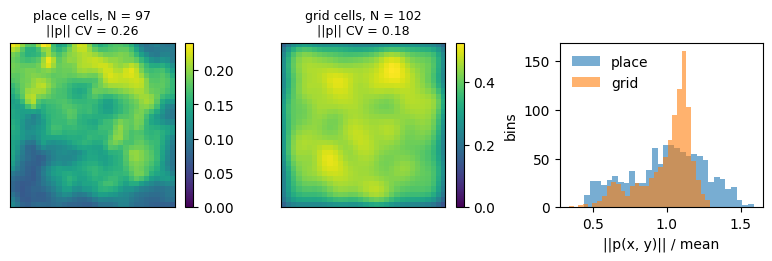

In [3]:
def norm_map(maps):
    return np.sqrt((maps**2).sum(axis=0))


grid = np.load(GRID_DATA)
fig, axs = plt.subplots(1, 3, figsize=(8, 2.5), layout="constrained")
for ax, maps, title in [(axs[0], experimental, f"place cells, N = {N_UNITS}"), (axs[1], grid, f"grid cells, N = {len(grid)}")]:
    nm = norm_map(maps)
    im = ax.imshow(nm.T, origin="lower", cmap="viridis", vmin=0)
    ax.set_title(f"{title}\n||p|| CV = {nm.std() / nm.mean():.2f}", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, fraction=0.046)
axs[2].hist(norm_map(experimental).ravel() / norm_map(experimental).mean(), bins=30, alpha=0.6, label="place")
axs[2].hist(norm_map(grid).ravel() / norm_map(grid).mean(), bins=30, alpha=0.6, label="grid")
axs[2].set_xlabel("||p(x, y)|| / mean")
axs[2].set_ylabel("bins")
axs[2].legend(frameon=False)
fig.savefig(FIGURE_DIR / "ca1_norm_map.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_norm_map.png", dpi=200, bbox_inches="tight")

# The error a perfect orthogonal model would make from norm variation alone: rescale each
# position's data vector to the mean norm and measure the change.
nm = norm_map(experimental)
equinorm_floor = np.sqrt(((experimental * (nm.mean() / nm - 1)) ** 2).mean()) / np.sqrt((experimental**2).mean())
print(f"relative error floor from norm variation alone: {equinorm_floor:.1%}")

## Fit

loss 8.437e-04 -> 2.840e-05


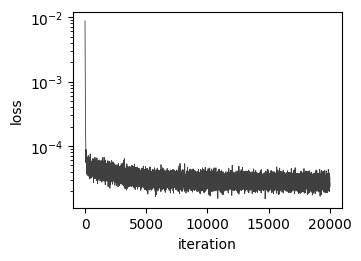

In [4]:
fit = GeneratorFit(n_units=N_UNITS, commutator_weight=COMMUTATOR_WEIGHT, lr=LR, seed=SEED)
loss_history = fit.fit(ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE, progress=False)
print(f"loss {np.mean(loss_history[:100]):.3e} -> {np.mean(loss_history[-100:]):.3e}")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.semilogy(loss_history, "k", linewidth=0.6, alpha=0.75)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")
fig.savefig(FIGURE_DIR / "ca1_fit_loss_curve.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_fit_loss_curve.png", dpi=200, bbox_inches="tight")

## Reconstruction within the arena

Generated by transporting the population vector at the arena centre to every pixel, as in
App. K, and compared with the data it was trained on. The relative RMS error is reported
overall and per unit, against the equinorm floor above.

relative reconstruction error 65.8% (equinorm floor 25.1%); per unit median 65.6%
per-unit correlation generated vs data: median 0.73, 10/90 pct 0.53/0.84


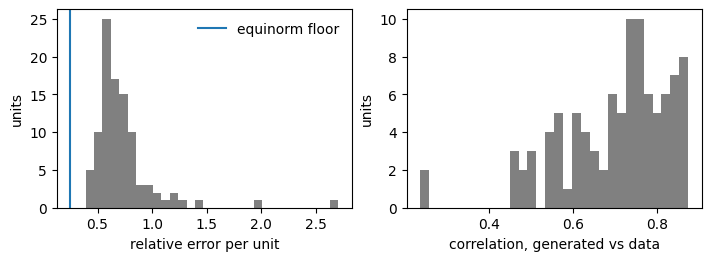

In [5]:
centre = ratemaps[N_BINS // 2, N_BINS // 2]
generated = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()

residual = generated - experimental
relative = np.sqrt((residual**2).mean()) / np.sqrt((experimental**2).mean())
per_unit = np.sqrt((residual**2).mean(axis=(1, 2))) / np.sqrt((experimental**2).mean(axis=(1, 2)))
correlation = np.array([np.corrcoef(g.ravel(), e.ravel())[0, 1] for g, e in zip(generated, experimental)])
print(f"relative reconstruction error {relative:.1%} (equinorm floor {equinorm_floor:.1%}); per unit median {np.median(per_unit):.1%}")
print(f"per-unit correlation generated vs data: median {np.median(correlation):.2f}, 10/90 pct {np.percentile(correlation, 10):.2f}/{np.percentile(correlation, 90):.2f}")

fig, axs = plt.subplots(1, 2, figsize=(7, 2.5), layout="constrained")
axs[0].hist(per_unit, bins=30, color="0.5")
axs[0].axvline(equinorm_floor, color="C0", label="equinorm floor")
axs[0].set_xlabel("relative error per unit")
axs[0].set_ylabel("units")
axs[0].legend(frameon=False)
axs[1].hist(correlation, bins=30, color="0.5")
axs[1].set_xlabel("correlation, generated vs data")
axs[1].set_ylabel("units")
fig.savefig(FIGURE_DIR / "ca1_fit_errors.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_fit_errors.png", dpi=200, bbox_inches="tight")

### Data and generation side by side

Units sorted by reconstruction correlation, best to worst, evenly sampled. Rows alternate
data and generation; each pair shares the unit's own scale. Maps in arena coordinates.

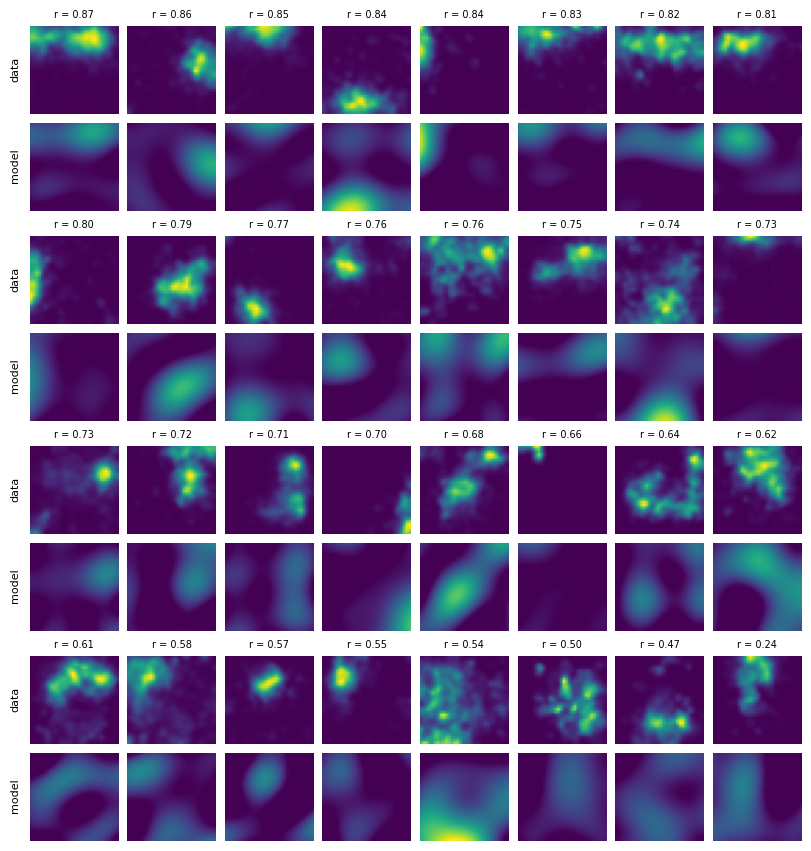

In [6]:
order = np.argsort(-correlation)
show = order[np.linspace(0, N_UNITS - 1, 32).astype(int)]
n_cols = 8
fig, axs = plt.subplots(8, n_cols, figsize=(n_cols * 1.0, 8 * 1.05), layout="constrained")
for ax in axs.ravel():
    ax.axis("off")
for j, k in enumerate(show):
    row, col = 2 * (j // n_cols), j % n_cols
    vmax = max(experimental[k].max(), generated[k].max())
    axs[row, col].imshow(experimental[k].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
    axs[row, col].set_title(f"r = {correlation[k]:.2f}", fontsize=7)
    axs[row + 1, col].imshow(generated[k].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
for row in range(0, 8, 2):
    axs[row, 0].text(-4, N_BINS / 2, "data", rotation=90, va="center", ha="right", fontsize=8)
    axs[row + 1, 0].text(-4, N_BINS / 2, "model", rotation=90, va="center", ha="right", fontsize=8)
fig.savefig(FIGURE_DIR / "ca1_fit_ratemaps.png", dpi=150, bbox_inches="tight")

## Against the noise ceiling

A ratemap from a 20-30 min session is a noisy estimate, so the data cannot be reproduced
to arbitrary precision by any model. The split-half correlation of a unit, between ratemaps
from the two halves of its session, is the ceiling for predicting one half from anything.
The model's correlation with each half is compared against it; `ca1.py` builds the half maps
with the same preprocessing. A synthetic population of this size built from the paper's own
construction is recovered by the same fit at correlation 0.99, so the gap to 1 here is in the
data, not in capacity or optimisation.

split-half ceiling: median 0.85;  model vs halves: median 0.69;  ratio median 0.84;  model above ceiling for 13 of 96 units


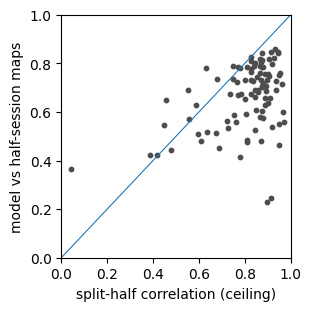

In [7]:
import sys

sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from ca1 import arena_box, load_events, population_ratemaps, preprocess_position, ratemap, select_units  # noqa: E402

sessions, units = load_events(REPO_ROOT / "data" / "ca1_events.npz")
rate_passing = select_units(units, tuple(d["rate_range"]))
_, _, information = population_ratemaps(sessions, units, rate_passing, N_BINS)
chosen = rate_passing[information >= float(d["info_threshold"])][keep]  # same units, same order as `experimental`

cache = {}
halves = []
for i in chosen:
    u, s = units[i], sessions[units[i].session]
    if u.session not in cache:
        xy, valid = preprocess_position(s)
        cache[u.session] = (xy, valid, arena_box(xy, valid))
    xy, valid, box = cache[u.session]
    first = s.t < s.t[-1] / 2
    halves.append([np.nan_to_num(ratemap(u.spike_t, s.t, xy, valid & half, box, N_BINS)[0]) for half in (first, ~first)])


def corr(a, b):
    return np.corrcoef(a.ravel(), b.ravel())[0, 1]


ceiling = np.array([corr(a, b) for a, b in halves])
model_half = np.array([0.5 * (corr(g, a) + corr(g, b)) for g, (a, b) in zip(generated, halves)])
ok = np.isfinite(ceiling) & np.isfinite(model_half)
print(f"split-half ceiling: median {np.median(ceiling[ok]):.2f};  model vs halves: median {np.median(model_half[ok]):.2f};  "
      f"ratio median {np.median(model_half[ok] / ceiling[ok]):.2f};  model above ceiling for {(model_half[ok] > ceiling[ok]).sum()} of {ok.sum()} units")

fig, ax = plt.subplots(figsize=(3, 3), layout="constrained")
ax.scatter(ceiling[ok], model_half[ok], s=10, color="0.3")
ax.plot([0, 1], [0, 1], color="C0", linewidth=0.8)
ax.set_xlabel("split-half correlation (ceiling)")
ax.set_ylabel("model vs half-session maps")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.savefig(FIGURE_DIR / "ca1_fit_ceiling.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_fit_ceiling.png", dpi=200, bbox_inches="tight")

## One-step prediction by displacement size

The training objective on held-out random pairs, split by displacement length. Steps of 1-2
pixels are what the fit saw; longer steps test whether the generators compose consistently
inside the arena, which is the path-integration property the commutator penalty is for.

In [8]:
generator = torch.Generator().manual_seed(SEED + 1)
start, end = sample_displacements(N_BINS, 20000, max_step=8, generator=generator)
dr = pixels_to_arena(end - start, N_BINS, ARENA_SIZE)
# In chunks: a batch of matrix exponentials costs several (batch, N, N) buffers at once.
with torch.no_grad():
    predicted = torch.cat(
        [fit.transport(ratemaps[s[:, 0], s[:, 1]], d) for s, d in zip(start.split(1000), dr.split(1000))]
    )
target = ratemaps[end[:, 0], end[:, 1]]
length = (end - start).abs().max(dim=1).values
error = ((predicted - target) ** 2).mean(dim=1).sqrt() / target.pow(2).mean(dim=1).sqrt()
step_error = {}
for n in range(0, 9):
    sel = length == n
    step_error[n] = float(error[sel].mean())
    print(f"  step {n} px: relative error {step_error[n]:.1%} over {int(sel.sum())} pairs")

  step 0 px: relative error 0.0% over 75 pairs
  step 1 px: relative error 23.2% over 536 pairs
  step 2 px: relative error 38.4% over 1155 pairs
  step 3 px: relative error 49.1% over 1622 pairs
  step 4 px: relative error 55.0% over 2250 pairs
  step 5 px: relative error 58.8% over 2762 pairs
  step 6 px: relative error 62.1% over 3326 pairs
  step 7 px: relative error 64.0% over 3774 pairs
  step 8 px: relative error 65.1% over 4500 pairs


## What the fit recovered

Commutator and norm preservation (structural for the enforced-skew fit), and the eigenvalue
spectra of the generators. The paper's place-like construction (App. H) draws the spectrum
from a Gaussian; what the data ask for is the question.

  commutator_rms             2.313e-04
  Gx_rms                     1.685e-01
  Gx_symmetric_fraction      0.000e+00
  Gy_rms                     1.816e-01
  Gy_symmetric_fraction      0.000e+00
  ||p|| over generated maps: 0.1438 +/- 5.9e-08  (data: 0.1512 +/- 0.0392)


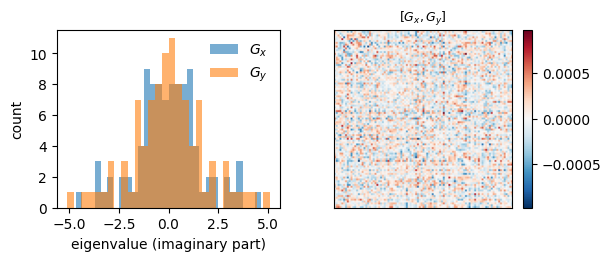

In [9]:
for name, value in generator_diagnostics(fit).items():
    print(f"  {name:26s} {value:.3e}")
norms = np.linalg.norm(generated.reshape(N_UNITS, -1), axis=0)
print(f"  ||p|| over generated maps: {norms.mean():.4f} +/- {norms.std():.1e}  (data: {norm_map(experimental).mean():.4f} +/- {norm_map(experimental).std():.4f})")

Gx, Gy = fit.Gx.detach().numpy(), fit.Gy.detach().numpy()
lx, ly = np.linalg.eigvals(Gx).imag, np.linalg.eigvals(Gy).imag
fig, axs = plt.subplots(1, 2, figsize=(6, 2.5), layout="constrained")
axs[0].hist(lx, bins=30, alpha=0.6, label=r"$G_x$")
axs[0].hist(ly, bins=30, alpha=0.6, label=r"$G_y$")
axs[0].set_xlabel("eigenvalue (imaginary part)")
axs[0].set_ylabel("count")
axs[0].legend(frameon=False)
im = axs[1].imshow(Gx @ Gy - Gy @ Gx, cmap="RdBu_r")
axs[1].set_title(r"$[G_x, G_y]$", fontsize=9)
axs[1].set_xticks([])
axs[1].set_yticks([])
fig.colorbar(im, ax=axs[1], fraction=0.046)
fig.savefig(FIGURE_DIR / "ca1_fit_generators.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_fit_generators.png", dpi=200, bbox_inches="tight")

## Save

Generators, loss history, the population used and its scale, so panels can be assembled
without refitting.

In [10]:
np.savez_compressed(
    OUTPUT,
    Gx=Gx,
    Gy=Gy,
    loss_history=np.array(loss_history),
    experimental=experimental,
    generated=generated,
    scale=SCALE,
    unit_mask=keep,
    seed=SEED,
    step_error=np.array([step_error[n] for n in range(9)]),
    relative_error=relative,
    correlation=correlation,
    split_half_ceiling=ceiling,
    model_vs_halves=model_half,
    n_steps=N_STEPS,
)
print(f"saved {OUTPUT.name}")

saved ca1_fit.npz
